# Phase 1 - The Matching Engine

A limit order book (LOB) is the data structure a modern exchange uses to organise resting buy and sell orders. This notebook drives our engine by hand to *show* the rules it enforces:

- **Price priority** - the best price always trades first (highest bid / lowest ask).
- **Time priority** - at the same price, the order that arrived first trades first (FIFO).
- **Partial fills** - a large order takes what liquidity it can and rests the rest.
- **Cancellation** - resting liquidity can be pulled in O(1).

Everything here is the *plumbing*: the 'easy half' of the project, but the foundation the RL market maker trades on top of.

In [1]:
from quant_mm.lob import MatchingEngine, Side, OrderType

def show_book(eng, depth=5):
    """Pretty-print the top `depth` levels of each side of the book."""
    asks = eng.book.depth(Side.ASK, depth)[::-1]  # show highest ask on top
    bids = eng.book.depth(Side.BID, depth)
    print(f"{'PRICE':>8} {'SIZE':>6}  SIDE")
    print('-' * 26)
    for p, v in asks:
        print(f"{p:>8.2f} {v:>6}  ASK")
    mid = eng.mid()
    print(f"{'  --- mid ' + (f'{mid:.2f}' if mid else 'n/a') + ' ---':^26}")
    for p, v in bids:
        print(f"{p:>8.2f} {v:>6}  BID")

## 1. Build a book
We rest some bids and asks. Nothing crosses (best bid < best ask), so it all stays in the book.

In [2]:
eng = MatchingEngine()
for price, qty in [(99.0, 10), (98.5, 8), (98.0, 12)]:
    eng.submit(Side.BID, quantity=qty, price=price)
for price, qty in [(100.0, 7), (100.5, 9), (101.0, 5)]:
    eng.submit(Side.ASK, quantity=qty, price=price)

show_book(eng)
print(f"\nbest bid={eng.best_bid()}  best ask={eng.best_ask()}  spread={eng.spread()}  imbalance={eng.book.imbalance():+.3f}")

   PRICE   SIZE  SIDE
--------------------------
  101.00      5  ASK
  100.50      9  ASK
  100.00      7  ASK
     --- mid 99.50 ---    
   99.00     10  BID
   98.50      8  BID
   98.00     12  BID

best bid=99.0  best ask=100.0  spread=1.0  imbalance=+0.176


## 2. Price priority
A marketable buy crosses into the asks. It must fill at the **lowest** ask (100.00) before any higher ask, regardless of order of entry.

In [3]:
order, trades = eng.submit(Side.BID, quantity=7, price=100.0)
for t in trades:
    print(t)
print('\nbest ask is now', eng.best_ask(), '(the 100.00 level was fully consumed)')

Trade(seq=7, bid aggressor #6 hit #3: 7 @ 100.0)

best ask is now 100.5 (the 100.00 level was fully consumed)


## 3. Time priority (FIFO within a price)
Two asks rest at the *same* price. The one entered first must fill first.

In [4]:
eng2 = MatchingEngine()
first, _ = eng2.submit(Side.ASK, quantity=5, price=100.0)   # arrives first
second, _ = eng2.submit(Side.ASK, quantity=5, price=100.0)  # arrives second
print(f'resting: first=#{first.id}, second=#{second.id} (both @ 100.00)')

_, trades = eng2.submit(Side.BID, quantity=5, price=100.0)
print('aggressor hit maker #', trades[0].maker_id, '-> the EARLIER order, as required')

resting: first=#0, second=#1 (both @ 100.00)
aggressor hit maker # 0 -> the EARLIER order, as required


## 4. Partial fill + resting remainder
A buy bigger than the available ask liquidity takes what it can, then **rests** the unfilled remainder as a new bid.

In [5]:
eng3 = MatchingEngine()
eng3.submit(Side.ASK, quantity=3, price=100.0)
order, trades = eng3.submit(Side.BID, quantity=10, price=100.0)
print(f'filled {sum(t.quantity for t in trades)} lots; {order.remaining} lots now rest as a bid @ {order.price}')
show_book(eng3)

filled 3 lots; 7 lots now rest as a bid @ 100.0
   PRICE   SIZE  SIDE
--------------------------
      --- mid n/a ---     
  100.00      7  BID


## 5. Sweeping multiple levels + a cancel
A large market order walks the book in price order. Then we show that cancelling resting liquidity makes the next order skip it.

In [6]:
eng4 = MatchingEngine()
a, _ = eng4.submit(Side.ASK, quantity=2, price=100.0)
eng4.submit(Side.ASK, quantity=2, price=101.0)
eng4.submit(Side.ASK, quantity=2, price=102.0)

_, trades = eng4.submit(Side.BID, quantity=5, price=None, order_type=OrderType.MARKET)
print('market buy swept:', [(t.price, t.quantity) for t in trades])

# Now cancel the best ask and watch the next buy skip straight to the next level.
eng5 = MatchingEngine()
best_ask_order, _ = eng5.submit(Side.ASK, quantity=5, price=100.0)
eng5.submit(Side.ASK, quantity=5, price=101.0)
eng5.cancel(best_ask_order.id)
_, trades = eng5.submit(Side.BID, quantity=5, price=101.0)
print('after cancelling the 100 ask, buy filled at', trades[0].price)

market buy swept: [(100.0, 2), (101.0, 2), (102.0, 1)]
after cancelling the 100 ask, buy filled at 101.0


## 6. Visualise the book
A depth chart - resting size at each price - the standard way traders eyeball liquidity.

Matplotlib is building the font cache; this may take a moment.


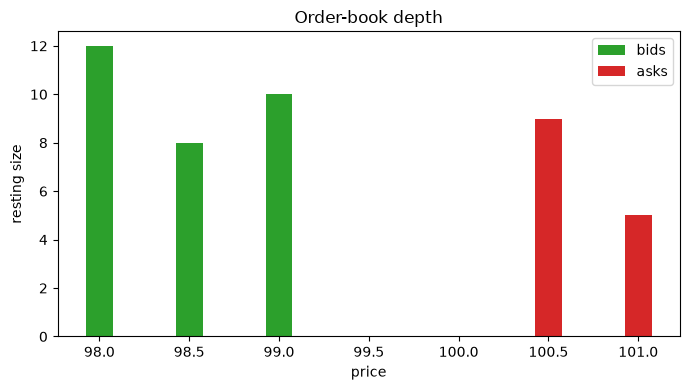

In [7]:
import matplotlib.pyplot as plt

bids = eng.book.depth(Side.BID, 5)
asks = eng.book.depth(Side.ASK, 5)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([p for p, _ in bids], [v for _, v in bids], width=0.15, color='tab:green', label='bids')
ax.bar([p for p, _ in asks], [v for _, v in asks], width=0.15, color='tab:red', label='asks')
ax.set_xlabel('price'); ax.set_ylabel('resting size'); ax.set_title('Order-book depth')
ax.legend(); plt.tight_layout(); plt.show()

---
**Takeaway.** The engine enforces price-time priority, handles partial fills, market orders, and O(1) cancels - verified by the 17 tests in `tests/`. This is the venue our market-making agent will quote into. Next: **Phase 2** - a stochastic market simulator and the Avellaneda-Stoikov quoting baseline.